# 04 — Pearson + Bayesian Belief Network + Classification Evaluation

### تحلیل روی داده‌های واقعی CommonsenseQA و ARC-Challenge

**هدف این نوت‌بوک:** انجام سه تسک جدید درس شناسایی الگو به‌عنوان یک آزمایش طبقه‌بندی مقدماتی.

- **کلاس ۰:** CommonsenseQA
- **کلاس ۱:** ARC-Challenge
- **ویژگی‌ها:** `question_words`، `question_chars`، `avg_option_words`

> این طبقه‌بندی، **تشخیص نوع دیتاست** است؛ **تشخیص Silent Failure یا درست/غلط بودن پاسخ LLM نیست**.

به دلایل روش‌شناختی، `option_count` وارد مدل نمی‌شود: این ویژگی تقریباً نوع دیتاست را لو می‌دهد. پارامترهای دسته‌بندی عددی فقط روی داده‌های آموزش محاسبه می‌شوند. تحلیل‌ها به GPU نیاز ندارند.

In [1]:
# Setup for Google Colab (runs automatically if inside Colab)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    if not Path('/content/drive').exists():
        drive.mount('/content/drive')
        print("Google Drive mounted at /content/drive")


## ۱. خواندن خروجی نوت‌بوک‌های قبلی

اگر `numeric_features.csv` در پوشه `outputs` قرار داشته باشد، همان استفاده می‌شود. اگر فقط `outputs.zip` موجود باشد، CSV از داخل ZIP خوانده می‌شود. مسیر را در صورت لزوم در `PROJECT_ROOT` اصلاح کنید.

In [2]:
from pathlib import Path
import io, zipfile, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, balanced_accuracy_score,
                             classification_report)

# Automatic project root detection (works in local project root, notebooks directory, or Google Colab)
def find_project_root():
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path('/content/drive/MyDrive/project'),
        Path('/content/drive/MyDrive/Detecting Silent Failures of Uncertainty Estimators'),
        Path('/content/drive/MyDrive'),
        Path('/content'),
        Path('/mnt/data'),
    ]
    # 1. Check direct candidate paths
    for cand in candidates:
        if (cand / 'outputs' / 'numeric_features.csv').exists() or (cand / 'outputs.zip').exists():
            return cand
    # 2. Check subdirectories of /content and /content/drive/MyDrive (in case repo was cloned or stored in a subfolder)
    for parent_dir in [Path('/content'), Path('/content/drive/MyDrive')]:
        if parent_dir.exists():
            try:
                for sub in parent_dir.iterdir():
                    if sub.is_dir() and ((sub / 'outputs' / 'numeric_features.csv').exists() or (sub / 'outputs.zip').exists()):
                        return sub
            except Exception:
                pass
    # 3. Fallback to candidate paths with datasets
    for cand in candidates:
        if (cand / 'datasets' / 'commonsense_qa').exists():
            return cand
    return Path.cwd()

BASE_DIR = find_project_root()
csv_path = BASE_DIR / 'outputs' / 'numeric_features.csv'
zip_path = BASE_DIR / 'outputs.zip'

if csv_path.exists():
    df = pd.read_csv(csv_path)
elif zip_path.exists():
    with zipfile.ZipFile(zip_path) as archive:
        df = pd.read_csv(io.BytesIO(archive.read('outputs/numeric_features.csv')))
elif (Path.cwd() / 'numeric_features.csv').exists():
    df = pd.read_csv(Path.cwd() / 'numeric_features.csv')
    BASE_DIR = Path.cwd()
else:
    raise FileNotFoundError(
        f"فایل outputs/numeric_features.csv یا outputs.zip در مسیرهای بررسی شده پیدا نشد.\n"
        f"مسیر فعلی: {Path.cwd()}\n"
        f"مسیر بررسی شده: {BASE_DIR}\n\n"
        f"علت خطا و راه‌حل‌ها:\n"
        f"1. اگر در Google Colab هستید، ابتدا نوت‌بوک 01_prepare_numeric_features.ipynb را اجرا کنید تا خروجی‌ها ایجاد شوند.\n"
        f"2. یا فایل outputs.zip یا پوشه outputs را مستقیماً در Colab آپلود کنید.\n"
        f"3. اگر فایل‌ها در Google Drive هستند، مطمئن شوید درایو Mount شده است و در صورت نیاز متغیر BASE_DIR را دستی آدرس‌دهی کنید:\n"
        f"   BASE_DIR = Path('/content/drive/MyDrive/نام_پوشه_پروژه')\n"
        f"4. اگر مخزن گیت را clone کرده‌اید، با دستور cd% وارد پوشه مخزن شوید: cd /content/Detecting...%"
    )

out = BASE_DIR / 'outputs' / 'classification'
out.mkdir(parents=True, exist_ok=True)
required = {'dataset', 'split', 'question_words', 'question_chars', 'avg_option_words', 'option_count'}
assert required.issubset(df.columns), f'فیلدهای مفقود: {required - set(df.columns)}'
print(f'Project ROOT: {BASE_DIR}')
print('Loaded:', len(df), 'rows')
print(pd.crosstab(df['dataset'], df['split']))
print('Results folder:', out)


Project ROOT: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators
Loaded: 14692 rows
split          test  train  validation
dataset                               
ARC-Challenge  1172   1119         299
CommonsenseQA  1140   9741        1221
Results folder: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\classification


## ۲. Pearson Correlation

یک ماتریس کلی و یک ماتریس برای **هر کلاس به‌صورت جداگانه** محاسبه می‌کنیم. به‌ویژه رابطه `question_words` و `question_chars` را در هر کلاس بررسی می‌کنیم. ضریب پیرسون فقط وابستگی **خطی** را می‌سنجد، نه همه انواع استقلال شرطی را.

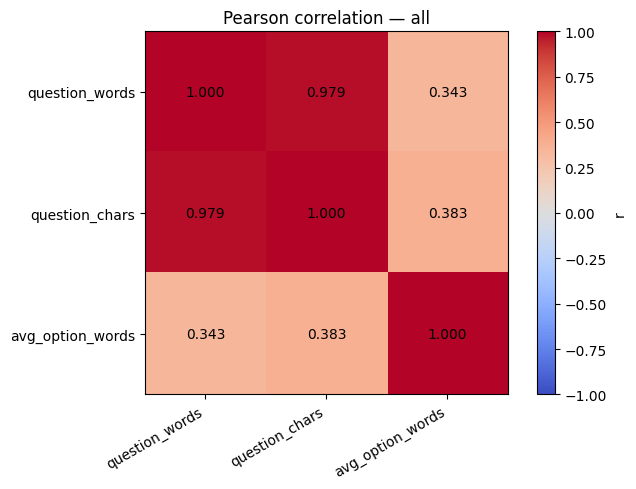

all : r(words,chars) = 0.979


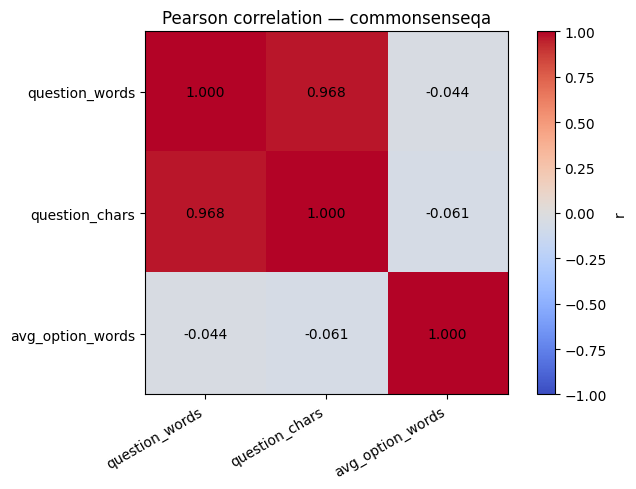

commonsenseqa : r(words,chars) = 0.968


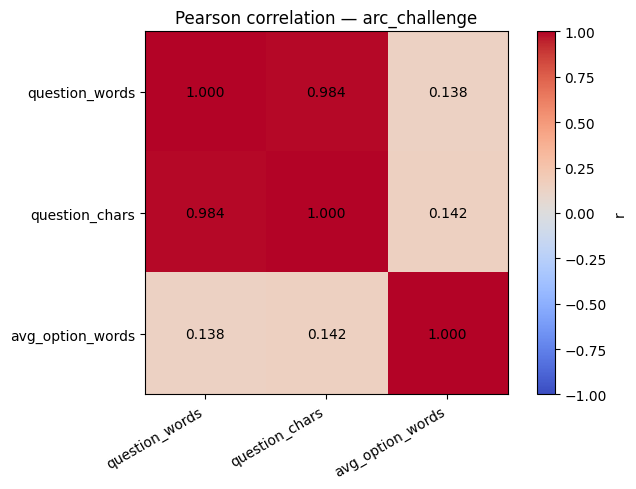

arc_challenge : r(words,chars) = 0.984


In [3]:
features = ['question_words','question_chars','avg_option_words']
for group_name, grp in [('all',df),('commonsenseqa',df[df.dataset=='CommonsenseQA']),
                        ('arc_challenge',df[df.dataset=='ARC-Challenge'])]:
    corr = grp[features].corr(method='pearson')
    corr.to_csv(out/f'pearson_{group_name}.csv', encoding='utf-8-sig')
    fig, ax = plt.subplots(figsize=(7,5))
    im = ax.imshow(corr.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(features)),labels=features,rotation=30,ha='right')
    ax.set_yticks(range(len(features)),labels=features)
    for i in range(len(features)):
        for j in range(len(features)):
            ax.text(j,i,f'{corr.iloc[i,j]:.3f}',ha='center',va='center')
    ax.set_title('Pearson correlation — '+group_name)
    fig.colorbar(im,ax=ax,label='r')
    fig.tight_layout()
    fig.savefig(out/f'pearson_{group_name}.png',dpi=160)
    plt.show()
    print(group_name,': r(words,chars) =',round(corr.loc['question_words','question_chars'],3))

## ۳. انتخاب کلاس و تفکیک صحیح Train / Test

برای این تمرین از **Splitهای از پیش موجود** استفاده می‌کنیم؛ آموزش روی Train و ارزیابی نهایی روی Test. چون Train در CommonsenseQA بسیار بزرگ‌تر است، برای آموزش از هر دیتاست به یک اندازه نمونه برمی‌داریم. **Test را دستکاری نمی‌کنیم** و همه نمونه‌های آن را ارزیابی می‌کنیم.

کلاس‌ها: `0 = CommonsenseQA` و `1 = ARC-Challenge`.

In [4]:
label_map = {'CommonsenseQA':0,'ARC-Challenge':1}
train = df[df['split']=='train'].copy()
test = df[df['split']=='test'].copy()
n_per_class = train['dataset'].value_counts().min()
train_balanced = pd.concat([g.sample(n=n_per_class,random_state=42)
                            for _,g in train.groupby('dataset')],ignore_index=True)
y_train = train_balanced['dataset'].map(label_map).to_numpy(dtype=int)
y_test = test['dataset'].map(label_map).to_numpy(dtype=int)
print('Train per class:',train_balanced.dataset.value_counts().to_dict())
print('Test per class:',test.dataset.value_counts().to_dict())
assert set(y_train)=={0,1} and set(y_test)=={0,1}

Train per class: {'ARC-Challenge': 1119, 'CommonsenseQA': 1119}
Test per class: {'ARC-Challenge': 1172, 'CommonsenseQA': 1140}


## ۴. تبدیل ویژگی‌های پیوسته به دسته‌ها (Discretization)

در این پیاده‌سازیِ **شبکه بیزی گسسته**، مقادیر هر ویژگی را به بازه‌هایی تقریباً چارکی تبدیل می‌کنیم. مرزهای بازه‌ها **فقط از Train** استخراج می‌شوند تا اطلاعات Test وارد آموزش نشود.

این مرحله **نرمال‌سازی Min-Max یا Z-Score نیست** و نیازی به تکرار نرمال‌سازی قبلی نداریم.

In [5]:
edges = {name: np.unique(np.quantile(train_balanced[name].to_numpy(float),[.25,.50,.75]))
         for name in features}
for name in features:
    print(f'{name}: bin borders = {edges[name]}')

def discretize(frame):
    return np.stack([np.searchsorted(edges[name],frame[name].to_numpy(float),side='right')
                     for name in features],axis=1)

X_train = discretize(train_balanced)
X_test = discretize(test)
n_bins = [len(edges[name])+1 for name in features]
print('Number of bins:',dict(zip(features,n_bins)))

question_words: bin borders = [10. 14. 21.]
question_chars: bin borders = [ 56.  78. 119.]
avg_option_words: bin borders = [1.25 1.8  4.75]
Number of bins: {'question_words': 4, 'question_chars': 4, 'avg_option_words': 4}


## ۵. Bayesian Belief Network (BBN)

یک شبکه بیزی گسسته با ساختار **ثابت و شفاف** می‌سازیم:

- `Class → question_words`
- `Class → question_chars`
- `question_words → question_chars` (**وابستگی داخل کلاس**)
- `Class → avg_option_words`

توزیع احتمال مشترک به این شکل فاکتور می‌شود:

\[
P(Y,W,C,O)=P(Y)P(W\mid Y)P(C\mid W,Y)P(O\mid Y)
\]

اینجا `Y` کلاس، `W` تعداد کلمات، `C` تعداد کاراکترها و `O` طول گزینه‌هاست. این ساختار علت و معلول را ثابت نمی‌کند؛ فقط یک مدل احتمالاتی از وابستگی‌هاست.

**یادگیری مدل:** جدول‌های احتمال شرطی (CPT) را از فراوانی‌های داده‌های Train با هموارسازی لاپلاس (`alpha=1`) حساب می‌کنیم. بنابراین نیازی به نصب `pgmpy` نیست؛ پیاده‌سازی زیر مستقیماً تعریف ریاضی یک BBN گسسته را اجرا می‌کند.

In [6]:
alpha = 1.0
counts_y = np.bincount(y_train,minlength=2).astype(float)+alpha
prior = counts_y/counts_y.sum()
# rows: Y; columns: bin(W)
counts_w = np.full((2,n_bins[0]),alpha,dtype=float)
# rows: Y; middle: bin(W); columns: bin(C)
counts_c_given_w = np.full((2,n_bins[0],n_bins[1]),alpha,dtype=float)
# rows: Y; columns: bin(O)
counts_o = np.full((2,n_bins[2]),alpha,dtype=float)

for y,(w,c,o) in zip(y_train,X_train):
    counts_w[y,w]+=1
    counts_c_given_w[y,w,c]+=1
    counts_o[y,o]+=1

p_w = counts_w / counts_w.sum(axis=1,keepdims=True)
p_c_given_w = counts_c_given_w / counts_c_given_w.sum(axis=2,keepdims=True)
p_o = counts_o / counts_o.sum(axis=1,keepdims=True)

# P(Y|W,C,O) متناسب با P(Y)P(W|Y)P(C|W,Y)P(O|Y)
log_score = np.column_stack([
    np.log(prior[y]) + np.log(p_w[y,X_test[:,0]]) +
    np.log(p_c_given_w[y,X_test[:,0],X_test[:,1]]) +
    np.log(p_o[y,X_test[:,2]])
    for y in (0,1)])
y_pred = log_score.argmax(axis=1)
print('BBN trained and predictions created:',len(y_pred))

BBN trained and predictions created: 2312


## ۶. Confusion Matrix و گزارش Performance

ماتریس با این ترتیب نمایش داده می‌شود: **سطرها کلاس واقعی** و **ستون‌ها کلاس پیش‌بینی‌شده** هستند. علاوه بر Accuracy، مقادیر Precision، Recall، F1 و Balanced Accuracy ذخیره می‌شوند.

Confusion matrix (actual rows / predicted columns):
 [[1046   94]
 [ 326  846]]
Accuracy: 0.8183
Balanced accuracy: 0.8197
               precision    recall  f1-score   support

CommonsenseQA       0.76      0.92      0.83      1140
ARC-Challenge       0.90      0.72      0.80      1172

     accuracy                           0.82      2312
    macro avg       0.83      0.82      0.82      2312
 weighted avg       0.83      0.82      0.82      2312



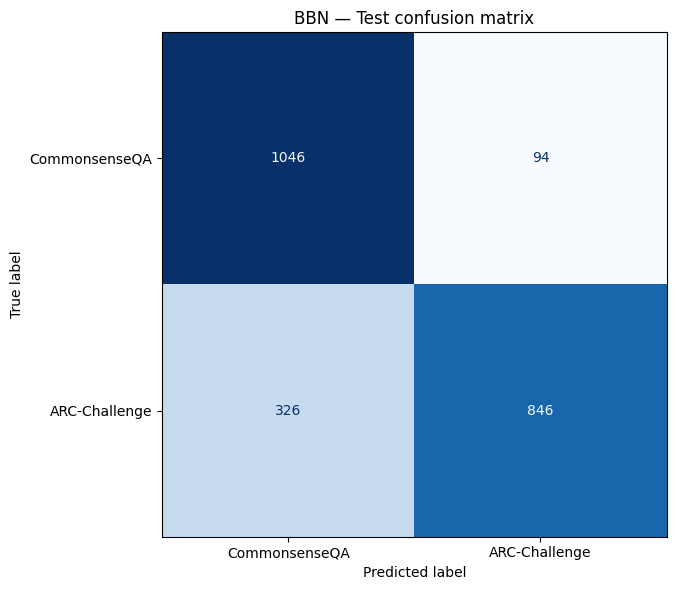

Saved results in: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\classification


In [7]:
label_names=['CommonsenseQA','ARC-Challenge']
cm=confusion_matrix(y_test,y_pred,labels=[0,1])
print('Confusion matrix (actual rows / predicted columns):\n',cm)
print('Accuracy:',round(accuracy_score(y_test,y_pred),4))
print('Balanced accuracy:',round(balanced_accuracy_score(y_test,y_pred),4))
print(classification_report(y_test,y_pred,labels=[0,1],target_names=label_names,zero_division=0))

fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=label_names).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('BBN — Test confusion matrix')
fig.tight_layout()
fig.savefig(out/'confusion_matrix_bbn.png',dpi=160)
plt.show()

pd.DataFrame(cm,index=['actual_'+n for n in label_names],
             columns=['predicted_'+n for n in label_names]).to_csv(out/'confusion_matrix_bbn.csv',encoding='utf-8-sig')
report=classification_report(y_test,y_pred,labels=[0,1],target_names=label_names,
                             zero_division=0,output_dict=True)
pd.DataFrame(report).transpose().to_csv(out/'classification_report_bbn.csv',encoding='utf-8-sig')
pd.DataFrame({'dataset_actual':test['dataset'].to_numpy(),'y_true':y_test,
              'y_pred':y_pred,'predicted_dataset':np.where(y_pred==0,'CommonsenseQA','ARC-Challenge')}).to_csv(
              out/'test_predictions_bbn.csv',index=False,encoding='utf-8-sig')
summary={'task':'dataset origin classification (NOT silent failure detection)',
         'model':'discrete Bayesian Belief Network with manually estimated CPTs and Laplace smoothing',
         'features':features,'excluded_feature':'option_count','classes':label_map,
         'n_train_balanced':len(y_train),'n_test':len(y_test),
         'accuracy':float(accuracy_score(y_test,y_pred)),
         'balanced_accuracy':float(balanced_accuracy_score(y_test,y_pred)),
         'confusion_matrix':cm.tolist(),
         'train_bins':{k:v.tolist() for k,v in edges.items()}}
(out/'run_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved results in:',out)

## ۷. برداشت درست از نتایج

- ضریب پیرسون در هر کلاس برای طول سؤال و تعداد کاراکترها بزرگ و مثبت است؛ پس **استقلال شرطی این دو متغیر به‌عنوان فرضی ساده، موجه به نظر نمی‌رسد**؛ ولی پیرسون به تنهایی آزمون کامل استقلال شرطی نیست.
- BBN انتخابی، وابستگی مستقیم `question_words → question_chars` را در احتمال‌ها مدل می‌کند.
- دقت طبقه‌بندی فقط نشان می‌دهد دو دیتاست با این **ویژگی‌های ساختاری** تا چه حد از هم قابل تشخیص‌اند؛ دقت تشخیص پاسخ غلط مدل زبانی یا Silent Failure نیست.
- برای پژوهش اصلی، بعد از اجرای LLM به برچسب `correct/incorrect` و ویژگی‌های اطمینان یا عدم‌قطعیت نیاز خواهیم داشت. 
- از داده‌های `Test` در تعیین مرز دسته‌ها و برآورد پارامترهای شبکه استفاده نشده است.